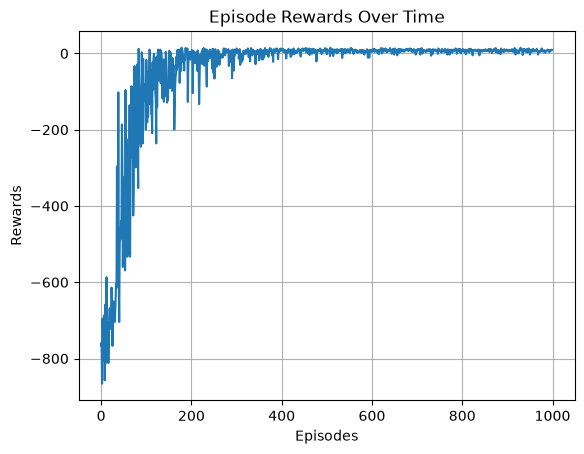

In [2]:

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Create Taxi environment
env = gym.make("Taxi-v4")

# Initialize Q-table
states = env.observation_space.n
actions = env.action_space.n

Q = np.zeros((states, actions))

# Hyperparameters
episodes = 1000
learning_rate = 0.7
discount = 0.618
epsilon = 1.0
epsilon_decay = 0.01

rewards = []

# Q-Learning
for ep in range(episodes):

    state, info = env.reset()
    done = False
    total_reward = 0

    while not done:

        # Exploration or Exploitation
        if np.random.uniform(0, 1) < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(Q[state])

        # Perform action
        next_state, reward, terminated, truncated, info = env.step(action)

        done = terminated or truncated

        # Update Q-table
        old_value = Q[state, action]
        next_max = np.max(Q[next_state])

        if terminated:
            Q[state, action] = old_value + learning_rate * (
                reward - old_value
            )
        else:
            Q[state, action] = old_value + learning_rate * (
                reward + discount * next_max - old_value
            )

        state = next_state
        total_reward += reward

    # Reduce exploration
    epsilon = max(0.01, epsilon - epsilon_decay)

    rewards.append(total_reward)

# Plot rewards
plt.plot(rewards)
plt.title("Episode Rewards Over Time")
plt.xlabel("Episodes")
plt.ylabel("Rewards")
plt.grid()
plt.show()

env.close()


# INSTALLATION COMMANDS (WINDOWS)
#
# 1. Create a virtual environment (optional):
#    python -m venv ml_env
#
# 2. Activate the virtual environment:
#    ml_env\Scripts\activate
#
# 3. Install required libraries:
#    python -m pip install "gymnasium[toy-text]" numpy matplotlib
#
# 4. Start Jupyter Notebook (if installed):
#    jupyter notebook
